# Retail Sales | Exploratory Data Analysis (EDA)

**Day 4 · ML Engineering Foundations**  
**Input:** Cleaned retail orders exported from the Day 3 Pandas workflow  
**Scope:** Data quality, univariate analysis, outliers, and category revenue comparisons

## Objective

Investigate retail order patterns and communicate findings through reproducible statistics and visualizations.

### Business questions

1. How are completed-order values distributed?
2. Are there unusually high-value orders, and are they plausible?
3. Which product categories, regions, and payment methods occur most frequently?
4. Which categories contribute the most **completed-order revenue**, and how does that compare with order volume?

**Business rule:** The cleaned dataset includes `Completed`, `Cancelled`, and `Pending` orders. Only `Completed` orders contribute to realized revenue metrics in this notebook. The original 80-row dataset remains available for general order-quality and status analysis.

**Tools:** Python, Pandas, Matplotlib, Seaborn, and Jupyter.

> **Status:** Analysis completed through category revenue comparisons. Regional revenue, time-series, and multivariate analysis will be developed in later stages; they have not been added prematurely.

## 1. Setup and data loading

Import libraries once and resolve paths relative to the **repository root**. A notebook's saved location and Jupyter's working directory can differ, so the code searches upward from the working directory for the Day 3 CSV file. All exported plots use the same resolved root.

In [1]:
# 1.1: Imports and notebook environment
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Python interpreter:", sys.executable)
print("Working directory:", Path.cwd())

Python interpreter: c:\Users\User\Desktop\ml-engineering-foundations\.venv\Scripts\python.exe
Working directory: c:\Users\User\Desktop\ml-engineering-foundations\eda\retail_sales_eda\notebooks


In [2]:
# 1.2: Locate the Day 3 dataset from the repository root
relative_data_path = Path(
    "pandas/retail_orders_analysis/outputs/cleaned_retail_orders.csv"
)

repo_root = next(
    (
        directory
        for directory in (Path.cwd(), *Path.cwd().parents)
        if (directory / relative_data_path).is_file()
    ),
    None,
)

if repo_root is None:
    raise FileNotFoundError(
        "Cannot locate the cleaned retail CSV. Start Jupyter from your "
        "ml-engineering-foundations repository (or a directory within it), "
        "and confirm the Day 3 CSV exists."
    )

data_path = repo_root / relative_data_path
figures_dir = repo_root / "eda/retail_sales_eda/outputs/figures"

print("Repository root:", repo_root)
print("Dataset path:", data_path)
print("Dataset exists:", data_path.is_file())

Repository root: c:\Users\User\Desktop\ml-engineering-foundations
Dataset path: c:\Users\User\Desktop\ml-engineering-foundations\pandas\retail_orders_analysis\outputs\cleaned_retail_orders.csv
Dataset exists: True


In [3]:
# 1.3: Load the cleaned CSV and restore date types for analysis
df = pd.read_csv(data_path)

# CSV stores dates as text. Parse them again after reading the file.
df["order_date"] = pd.to_datetime(df["order_date"], format="%Y-%m-%d")

# Keep order_month as a YYYY-MM label. Check it against the parsed date.
month_matches = (
    df["order_date"].dt.strftime("%Y-%m") == df["order_month"]
)
print("Date/month values consistent:", month_matches.all())

display(df.head())

Date/month values consistent: True


,order_id,order_date,customer_id,region,product,category,quantity,unit_price,discount_pct,payment_method,order_status,gross_revenue,discount_amount,net_revenue,order_month
0,ORD-1001,2026-07-04,CUST-108,Abuja,Mechanical Keyboard,Electronics,3,75.0,0.0,Cash,Completed,225.0,0.0,225.0,2026-07
1,ORD-1002,2026-07-12,CUST-102,Lagos,Standing Desk,Furniture,5,320.0,5.0,Card,Completed,1600.0,80.0,1520.0,2026-07
2,ORD-1003,2026-09-03,CUST-118,Abuja,Laptop Stand,Accessories,5,35.0,0.0,Cash,Cancelled,175.0,0.0,175.0,2026-09
3,ORD-1004,2026-08-23,CUST-119,Ibadan,Standing Desk,Furniture,2,320.0,5.0,Card,Completed,640.0,32.0,608.0,2026-08
4,ORD-1005,2026-08-13,CUST-107,Ibadan,Notebook Set,Stationery,3,12.0,0.0,Card,Completed,36.0,0.0,36.0,2026-08


In [4]:
# 1.4: Understand the shape, columns, and data types
print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nDataset information:")
df.info()

Dataset shape: (80, 15)

Column names: ['order_id', 'order_date', 'customer_id', 'region', 'product', 'category', 'quantity', 'unit_price', 'discount_pct', 'payment_method', 'order_status', 'gross_revenue', 'discount_amount', 'net_revenue', 'order_month']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 80 entries, 0 to 79
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         80 non-null     str           
 1   order_date       80 non-null     datetime64[us]
 2   customer_id      79 non-null     str           
 3   region           80 non-null     str           
 4   product          80 non-null     str           
 5   category         80 non-null     str           
 6   quantity         80 non-null     int64         
 7   unit_price       80 non-null     float64       
 8   discount_pct     80 non-null     float64       
 9   payment_method   80 non-null     str      

## 2. Data quality and business rules

Before drawing conclusions, check missing values, duplicated order IDs, order statuses, and basic numerical summaries. A missing customer ID does not automatically make the entire order invalid; whether to exclude it depends on the question being investigated.

In [5]:
# 2.1: Check completeness and order identifier uniqueness
missing_values = df.isna().sum()

print("Missing values by column:")
print(missing_values)
print("\nTotal missing values:", missing_values.sum())
print("Repeated order IDs:", df["order_id"].duplicated().sum())
print("\nOrder status counts:")
print(df["order_status"].value_counts(dropna=False))

Missing values by column:
order_id           0
order_date         0
customer_id        1
region             0
product            0
category           0
quantity           0
unit_price         0
discount_pct       0
payment_method     0
order_status       0
gross_revenue      0
discount_amount    0
net_revenue        0
order_month        0
dtype: int64

Total missing values: 1
Repeated order IDs: 0

Order status counts:
order_status
Completed    51
Cancelled    17
Pending      12
Name: count, dtype: int64


### 2.2 Full-dataset descriptive statistics

These summaries describe **all order records**, including pending and cancelled orders. They help us inspect recorded values and data quality; they are **not** estimates of realized sales performance.

In [6]:
# Numerical summaries for all recorded orders
numeric_columns = [
    "quantity", "unit_price", "discount_pct",
    "gross_revenue", "discount_amount", "net_revenue",
]

summary_stats = df[numeric_columns].describe().T
display(summary_stats.round(2))

,count,mean,std,min,25%,50%,75%,max
quantity,80.0,3.29,1.38,1.0,2.00,3.0,4.25,5.0
unit_price,80.0,84.86,90.80,12.0,33.75,60.0,78.75,320.0
discount_pct,80.0,4.38,5.42,0.0,0.00,0.0,10.00,15.0
gross_revenue,80.0,292.99,394.12,12.0,90.00,145.0,300.00,1600.0
discount_amount,80.0,11.67,23.98,0.0,0.00,0.0,13.50,144.0
net_revenue,80.0,281.32,384.58,12.0,79.88,140.0,277.50,1600.0


### 2.3 Define the completed-order population

We preserve `df` for operational questions and create a separate `completed_df` for realized revenue analysis. `.copy()` produces an independent DataFrame for further exploration.

**Unit of analysis:** The inspected source has unique `order_id` values, so each record represents one order in this dataset.

In [7]:
# Filter to Completed orders for all realized-revenue calculations
completed_df = df.loc[df["order_status"] == "Completed"].copy()

if completed_df.empty:
    raise ValueError("No Completed orders were found; check order_status values.")

print("All orders:", len(df))
print("Completed orders:", len(completed_df))
print("Pending/cancelled orders:", len(df) - len(completed_df))
print("\nStatuses retained:")
print(completed_df["order_status"].value_counts())

All orders: 80
Completed orders: 51
Pending/cancelled orders: 29

Statuses retained:
order_status
Completed    51
Name: count, dtype: int64


## 3. Univariate EDA — completed-order revenue

Univariate analysis studies **one variable at a time**. First inspect summary statistics; then use a histogram for distribution shape and a box plot for potential outliers.

In [8]:
# 3.1: Revenue summary for completed orders only
completed_revenue_stats = completed_df["net_revenue"].describe()
print("Net revenue per completed order:")
print(completed_revenue_stats.round(2))

Net revenue per completed order:
count      51.00
mean      299.90
std       428.83
min        12.00
25%        63.75
50%       140.00
75%       255.75
max      1600.00
Name: net_revenue, dtype: float64


### 3.2 Histogram: distribution shape

A histogram groups numeric observations into intervals. A concentration of low values with a long tail extending toward high values is called **right-skewed** (positively skewed). The tail, not the location of the tallest bars, determines the skew direction.

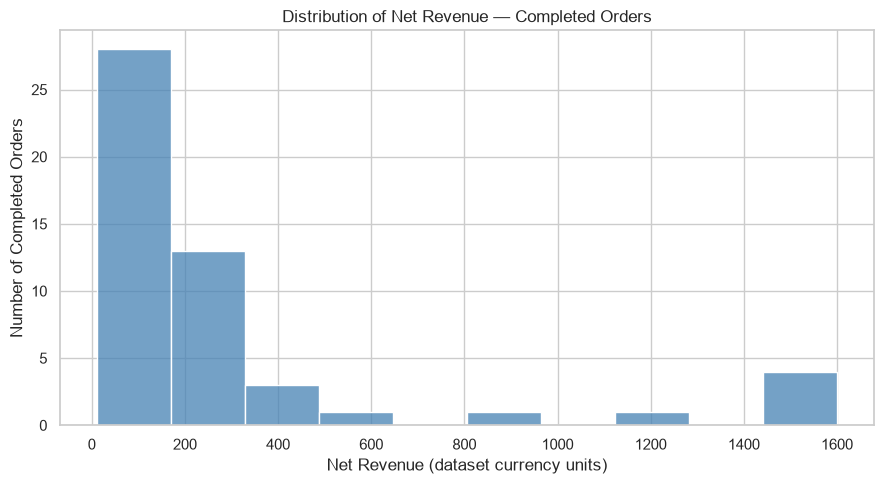

In [9]:
# Distribution of completed-order revenue
fig, ax = plt.subplots(figsize=(9, 5))
sns.histplot(
    data=completed_df,
    x="net_revenue",
    bins=10,
    edgecolor="white",
    color="steelblue",
    ax=ax,
)
ax.set_title("Distribution of Net Revenue — Completed Orders")
ax.set_xlabel("Net Revenue (dataset currency units)")
ax.set_ylabel("Number of Completed Orders")
fig.tight_layout()
plt.show()

### 3.3 Box plot: outlier screening

The box spans the 25th to 75th percentiles (Q1–Q3); the line in the box marks the median. Individual points beyond the whiskers may be unusual, but **a flagged observation is not automatically a data error**.

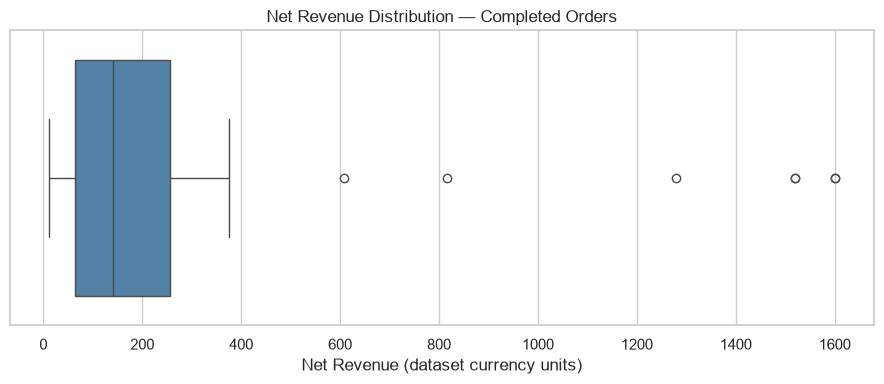

In [10]:
# Box plot for completed-order net revenue
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=completed_df, x="net_revenue", color="steelblue", ax=ax)
ax.set_title("Net Revenue Distribution — Completed Orders")
ax.set_xlabel("Net Revenue (dataset currency units)")
fig.tight_layout()
plt.show()

### 3.4 Outliers using the interquartile range (IQR)

The IQR is the spread of the middle 50% of observations:

\[
IQR = Q3 - Q1
\]

Potential outliers are values below \(Q1 - 1.5\times IQR\) or above \(Q3 + 1.5\times IQR\). These are **screening thresholds**, not instructions to delete records.

In [11]:
# Detect potential outliers among completed orders
q1 = completed_df["net_revenue"].quantile(0.25)
q3 = completed_df["net_revenue"].quantile(0.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

outliers = completed_df.loc[
    (completed_df["net_revenue"] < lower_fence)
    | (completed_df["net_revenue"] > upper_fence)
].copy()

print(f"Q1: {q1:.2f} | Q3: {q3:.2f} | IQR: {iqr:.2f}")
print(f"Lower fence: {lower_fence:.2f}")
print(f"Upper fence: {upper_fence:.2f}")
print("Potential outliers:", len(outliers))

display(
    outliers[
        [
            "order_id", "product", "category", "quantity",
            "unit_price", "discount_pct", "net_revenue",
        ]
    ].sort_values("net_revenue", ascending=False)
)

Q1: 63.75 | Q3: 255.75 | IQR: 192.00
Lower fence: -224.25
Upper fence: 543.75
Potential outliers: 7


,order_id,product,category,quantity,unit_price,discount_pct,net_revenue
47,ORD-1048,Standing Desk,Furniture,5,320.0,0.0,1600.0
59,ORD-1060,Standing Desk,Furniture,5,320.0,0.0,1600.0
1,ORD-1002,Standing Desk,Furniture,5,320.0,5.0,1520.0
74,ORD-1075,Standing Desk,Furniture,5,320.0,5.0,1520.0
64,ORD-1065,Standing Desk,Furniture,4,320.0,0.0,1280.0
20,ORD-1021,Standing Desk,Furniture,3,320.0,15.0,816.0
3,ORD-1004,Standing Desk,Furniture,2,320.0,5.0,608.0


### 3.5 Revenue concentration and outlier impact

Calculate the share of both completed **orders** and completed **revenue** represented by flagged transactions. A small share of orders can contribute a large share of revenue.

In [12]:
# Contribution of IQR-flagged transactions to completed-order revenue
total_revenue = completed_df["net_revenue"].sum()
outlier_revenue = outliers["net_revenue"].sum()

outlier_order_pct = 100 * len(outliers) / len(completed_df)
outlier_revenue_pct = 100 * outlier_revenue / total_revenue

print(f"Total completed revenue: {total_revenue:,.2f}")
print(f"Revenue from potential outliers: {outlier_revenue:,.2f}")
print(f"Share of completed orders: {outlier_order_pct:.2f}%")
print(f"Share of completed revenue: {outlier_revenue_pct:.2f}%")

Total completed revenue: 15,295.05
Revenue from potential outliers: 8,944.00
Share of completed orders: 13.73%
Share of completed revenue: 58.48%


**Finding 1 — Right-skewed revenue and concentration**

For the Day 3 cleaned dataset analyzed here, 51 orders were completed. Completed-order revenue was right-skewed: the median was 140.00 and the mean was 299.90.

The IQR method flagged **7 orders**, with a combined net revenue of **8,944.00**. They comprised **13.73% of completed orders** but generated **58.48% of completed-order revenue** (15,295.05). All seven involved Standing Desks in the Furniture category.

**Interpretation:** High-value, multi-unit Standing Desk purchases appear to explain the large right tail; this is plausible but not independently verified against original receipts. Keep the records for now: an IQR flag alone does not justify deleting legitimate transactions.

> The values above describe this specific dataset snapshot. If the source CSV changes, rerun the notebook and update the narrative to match the new outputs.

## 4. Univariate EDA — categorical variables

For categorical variables, `value_counts()` and `sns.countplot()` summarize **frequencies**, not revenue. In our dataset, completed orders and units sold are different quantities.

### 4.1 Product category frequency

Compare all orders with completed orders, then visualize completed-order counts.

In [13]:
# Product-category frequencies
all_categories = df["category"].value_counts()
completed_categories = completed_df["category"].value_counts()

print("All orders by category:")
print(all_categories)
print("\nCompleted orders by category:")
print(completed_categories)

All orders by category:
category
Electronics    42
Furniture      12
Accessories    12
Stationery      7
Home Office     7
Name: count, dtype: int64

Completed orders by category:
category
Electronics    27
Furniture       7
Home Office     6
Accessories     6
Stationery      5
Name: count, dtype: int64


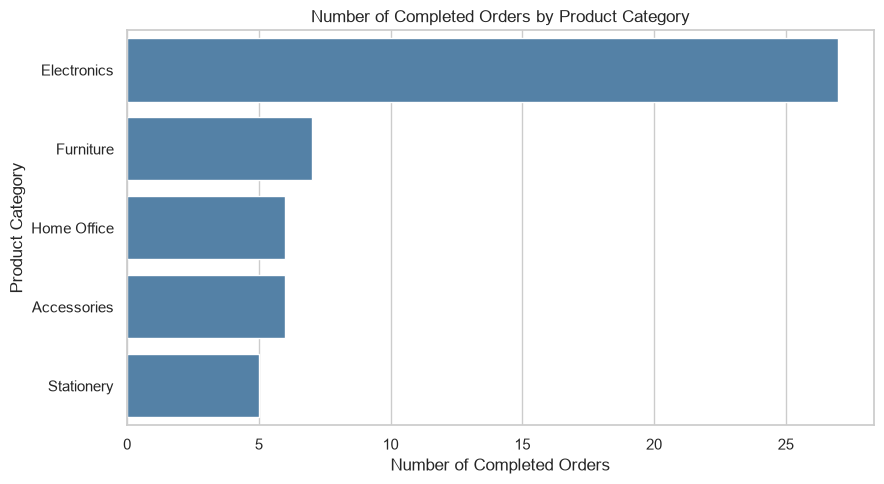

In [14]:
# Completed orders by product category
fig, ax = plt.subplots(figsize=(9, 5))
sns.countplot(
    data=completed_df,
    y="category",
    order=completed_categories.index,
    color="steelblue",
    ax=ax,
)
ax.set_title("Number of Completed Orders by Product Category")
ax.set_xlabel("Number of Completed Orders")
ax.set_ylabel("Product Category")
fig.tight_layout()
plt.show()

### 4.2 Regional order frequency

Which region has the highest **number of completed orders**? This chart measures volume only; a regional revenue comparison is planned for the next stage.

Completed orders by region:
region
Abuja            15
Lagos            14
Ibadan           12
Port Harcourt    10
Name: count, dtype: int64


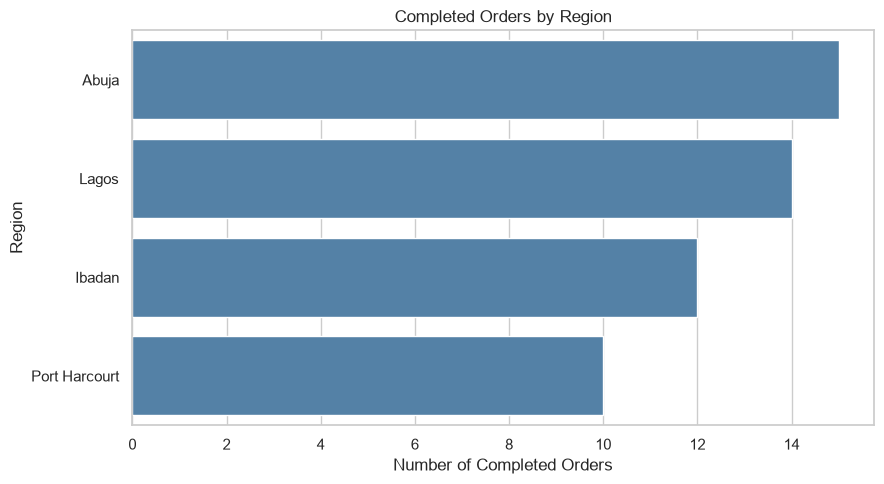

In [15]:
# Completed-order counts by region
region_counts = completed_df["region"].value_counts()
print("Completed orders by region:")
print(region_counts)

fig, ax = plt.subplots(figsize=(9, 5))
sns.countplot(
    data=completed_df,
    y="region",
    order=region_counts.index,
    color="steelblue",
    ax=ax,
)
ax.set_title("Completed Orders by Region")
ax.set_xlabel("Number of Completed Orders")
ax.set_ylabel("Region")
fig.tight_layout()
plt.show()

### 4.3 Payment methods among completed orders

This chart describes payment methods **among successful orders**. It does not establish overall customer payment preferences or whether a method improves completion rates.

Completed orders by payment method:
payment_method
Card        21
Cash        16
Transfer    14
Name: count, dtype: int64


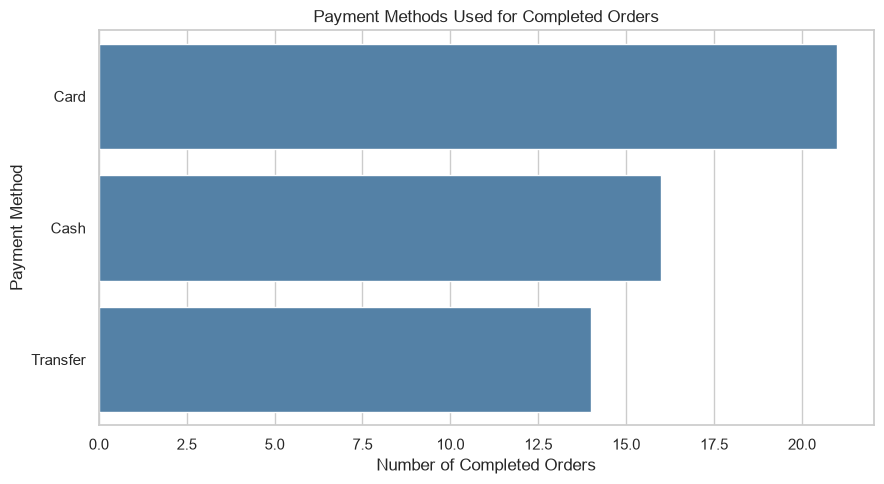

In [16]:
# Completed-order counts by payment method
payment_counts = completed_df["payment_method"].value_counts()
print("Completed orders by payment method:")
print(payment_counts)

fig, ax = plt.subplots(figsize=(9, 5))
sns.countplot(
    data=completed_df,
    y="payment_method",
    order=payment_counts.index,
    color="steelblue",
    ax=ax,
)
ax.set_title("Payment Methods Used for Completed Orders")
ax.set_xlabel("Number of Completed Orders")
ax.set_ylabel("Payment Method")
fig.tight_layout()
plt.show()

**Finding 2 — Completed-order frequencies**

- **Electronics** leads completed-order count (27 out of 51); this is not the same as leading revenue.
- **Abuja** has the highest count (15), just one more than **Lagos** (14). A one-order difference should not be overstated.
- **Card** is the most common payment method among completed orders (21 of 51).

These figures suggest transaction patterns, **not customer retention or churn**. Retention would require tracking `customer_id` and repeat purchases over time.

## 5. Bivariate EDA — category performance

**Business question:** Does the product category with the most completed orders also generate the most completed-order net revenue?

Here we compare category (categorical) with numerical metrics, including revenue, order count, and quantity. Revenue represents recorded net revenue **from completed orders only**.

In [17]:
# 5.1: Summarize completed-order performance by category
category_performance = (
    completed_df
    .groupby("category")
    .agg(
        completed_orders=("order_id", "nunique"),
        total_revenue=("net_revenue", "sum"),
        average_order_value=("net_revenue", "mean"),
        units_sold=("quantity", "sum"),
    )
    .sort_values("total_revenue", ascending=False)
)

display(category_performance.round(2))

,completed_orders,total_revenue,average_order_value,units_sold
category,,,,
Furniture,7,8944.00,1277.71,29
Electronics,27,4986.75,184.69,83
Accessories,6,665.00,110.83,20
Home Office,6,520.50,86.75,19
Stationery,5,178.80,35.76,15


In [18]:
# 5.2: Category share of completed-order net revenue
category_performance["revenue_share_pct"] = (
    100 * category_performance["total_revenue"]
    / category_performance["total_revenue"].sum()
)

display(category_performance.round(2))

,completed_orders,total_revenue,average_order_value,units_sold,revenue_share_pct
category,,,,,
Furniture,7,8944.00,1277.71,29,58.48
Electronics,27,4986.75,184.69,83,32.60
Accessories,6,665.00,110.83,20,4.35
Home Office,6,520.50,86.75,19,3.40
Stationery,5,178.80,35.76,15,1.17


### 5.3 Revenue bar chart and portfolio export

Use the already-aggregated category table; each category appears **once**. Plot category totals in descending order, label each bar, and save the image under `eda/retail_sales_eda/outputs/figures/`. Saving uses `repo_root`, so the output path remains correct even when the notebook is relocated.

Figure saved to: c:\Users\User\Desktop\ml-engineering-foundations\eda\retail_sales_eda\outputs\figures\category_revenue_completed.png


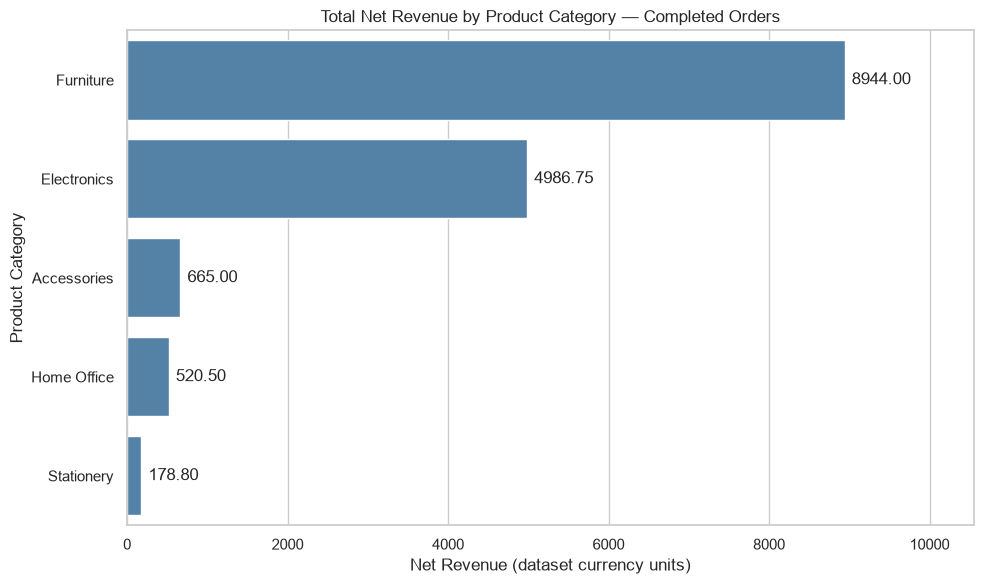

In [19]:
# Completed revenue by category — portfolio figure
plot_data = category_performance.reset_index()
fig, ax = plt.subplots(figsize=(10, 6))

# One pre-aggregated total per category; do not average raw order rows.
sns.barplot(
    data=plot_data,
    x="total_revenue",
    y="category",
    order=category_performance.index,
    errorbar=None,
    color="steelblue",
    ax=ax,
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=5)

ax.set_xlim(0, category_performance["total_revenue"].max() * 1.18)
ax.set_title("Total Net Revenue by Product Category — Completed Orders")
ax.set_xlabel("Net Revenue (dataset currency units)")
ax.set_ylabel("Product Category")
fig.tight_layout()

figures_dir.mkdir(parents=True, exist_ok=True)
figure_path = figures_dir / "category_revenue_completed.png"
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
print("Figure saved to:", figure_path)
plt.show()

**Finding 3 — Order volume versus sales value**

| Category | Completed orders | Net revenue | Average order value | Revenue share |
|:--|--:|--:|--:|--:|
| Furniture | 7 | 8,944.00 | 1,277.71 | 58.48% |
| Electronics | 27 | 4,986.75 | 184.69 | 32.60% |
| Accessories | 6 | 665.00 | 110.83 | 4.35% |
| Home Office | 6 | 520.50 | 86.75 | 3.40% |
| Stationery | 5 | 178.80 | 35.76 | 1.17% |

Electronics generated the most completed orders, but Furniture generated the most completed-order revenue. Furniture's high average order value was driven here by seven Standing Desk orders. **Revenue is not profit**; a product investment recommendation would also need costs, margins, inventory considerations, and more historical data.

The table reflects the specific Day 3 dataset snapshot; recheck these figures if the CSV changes.


## 6. Bivariate EDA — Regional Performance

### 6.1 Completed-Order Revenue by Region

**Business question:** Does the region with the highest
completed-order volume also generate the highest net revenue?

This analysis considers completed orders only.

We will compare:
- Completed-order counts
- Total net revenue
- Average order value
- Units sold
- Regional revenue contribution


In [20]:
# Step 21: Analyze completed-order performance by region

region_performance = (
    completed_df
    .groupby("region")
    .agg(
        completed_orders=("order_id", "nunique"),
        total_revenue=("net_revenue", "sum"),
        average_order_value=("net_revenue", "mean"),
        units_sold=("quantity", "sum")
    )
    .sort_values("total_revenue", ascending=False)
)

display(region_performance.round(2))

,completed_orders,total_revenue,average_order_value,units_sold
region,,,,
Lagos,14,5905.25,421.80,43
Ibadan,12,3563.50,296.96,45
Port Harcourt,10,2915.30,291.53,37
Abuja,15,2911.00,194.07,41


In [21]:
# Step 22: Calculate each region's contribution to revenue

region_performance["revenue_share_pct"] = (
    region_performance["total_revenue"]
    / region_performance["total_revenue"].sum()
) * 100

print("Regional performance summary:")
display(region_performance.round(2))

# Validate our regional totals
print(
    "Total completed orders:",
    region_performance["completed_orders"].sum()
)

print(
    "Total completed revenue:",
    round(region_performance["total_revenue"].sum(), 2)
)

Regional performance summary:


,completed_orders,total_revenue,average_order_value,units_sold,revenue_share_pct
region,,,,,
Lagos,14,5905.25,421.80,43,38.61
Ibadan,12,3563.50,296.96,45,23.30
Port Harcourt,10,2915.30,291.53,37,19.06
Abuja,15,2911.00,194.07,41,19.03


Total completed orders: 51
Total completed revenue: 15295.05


### 6.2 Regional Net Revenue Visualization

Compare total completed-order revenue across regions
to identify geographical differences in sales performance.

Figure saved to: c:\Users\User\Desktop\ml-engineering-foundations\eda\retail_sales_eda\outputs\figures\region_revenue_completed.png


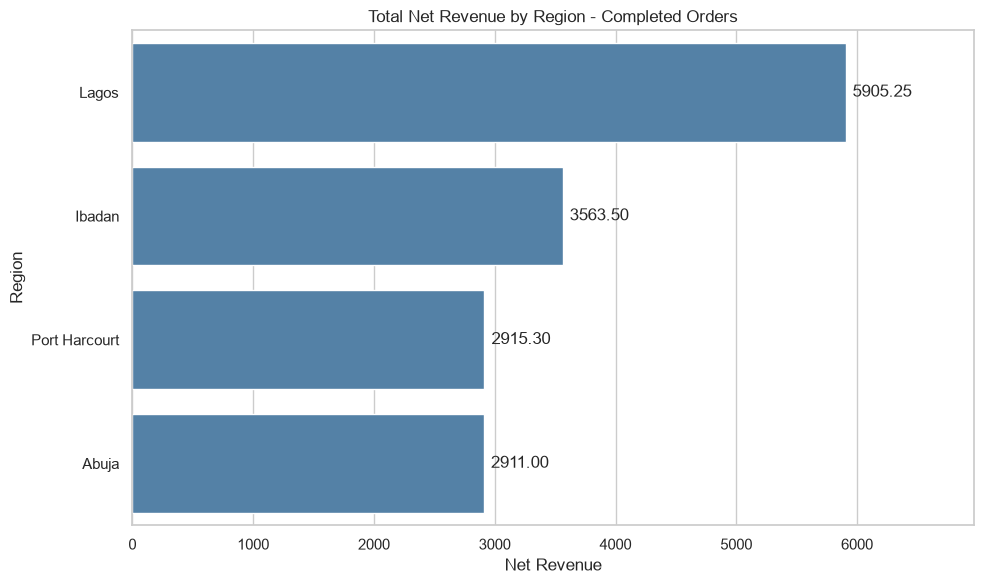

In [23]:
# Step 23: Visualize completed-order revenue by region

# Convert region index into a regular column.
region_plot_data = region_performance.reset_index()

fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=region_plot_data,
    x="total_revenue",
    y="region",
    order=region_performance.index,
    errorbar=None,
    color="steelblue",
    ax=ax
)

# Display revenue amounts beside each bar.
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=5
    )

# Leave space for the revenue labels.
ax.set_xlim(
    0,
    region_performance["total_revenue"].max() * 1.18
)

ax.set_title(
    "Total Net Revenue by Region - Completed Orders"
)
ax.set_xlabel("Net Revenue")
ax.set_ylabel("Region")

fig.tight_layout()

# Save the chart in our portfolio figures directory.
figures_dir.mkdir(parents=True, exist_ok=True)

figure_path = figures_dir / "region_revenue_completed.png"

fig.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight"
)

print("Figure saved to:", figure_path)

plt.show()


### 6.3 Regional Revenue by Product Category

**Business question:** Which product categories generate the
most revenue within each region?

This analysis investigates whether regional revenue
differences are associated with the product categories
purchased.

Only completed orders are included.


In [ ]:
# Step 24: Analyze revenue by region and product category

region_category_revenue = completed_df.pivot_table(
    index="region",          # Region as the row index
    columns="category",      # Product category as the column index
    values="net_revenue",    # Values to aggregate
    aggfunc="sum",           # Sum the net revenue for each combination
    fill_value=0             # Fill missing values with 0
)

print("Revenue by region and product category:")

display(region_category_revenue.round(2))

# Verify that our pivot table preserves total revenue.
print(
    "\nTotal revenue:",
    f"{region_category_revenue.to_numpy().sum():,.2f}"
)

Revenue by region and product category:


category,Accessories,Electronics,Furniture,Home Office,Stationery
region,,,,,
Abuja,374.5,1708.50,816.0,0.0,12.0
Ibadan,0.0,1365.00,1888.0,166.5,144.0
Lagos,231.0,849.25,4720.0,105.0,0.0
Port Harcourt,59.5,1064.00,1520.0,249.0,22.8



Total revenue: 15,295.05


### 6.4 Regional Revenue Heatmap

**Business question:** How does product-category revenue
vary across geographical regions?

A heatmap is used to highlight high-revenue combinations
of regions and product categories.

Only completed orders are included.

Heatmap saved to: c:\Users\User\Desktop\ml-engineering-foundations\eda\retail_sales_eda\outputs\figures\region_category_revenue_heatmap.png


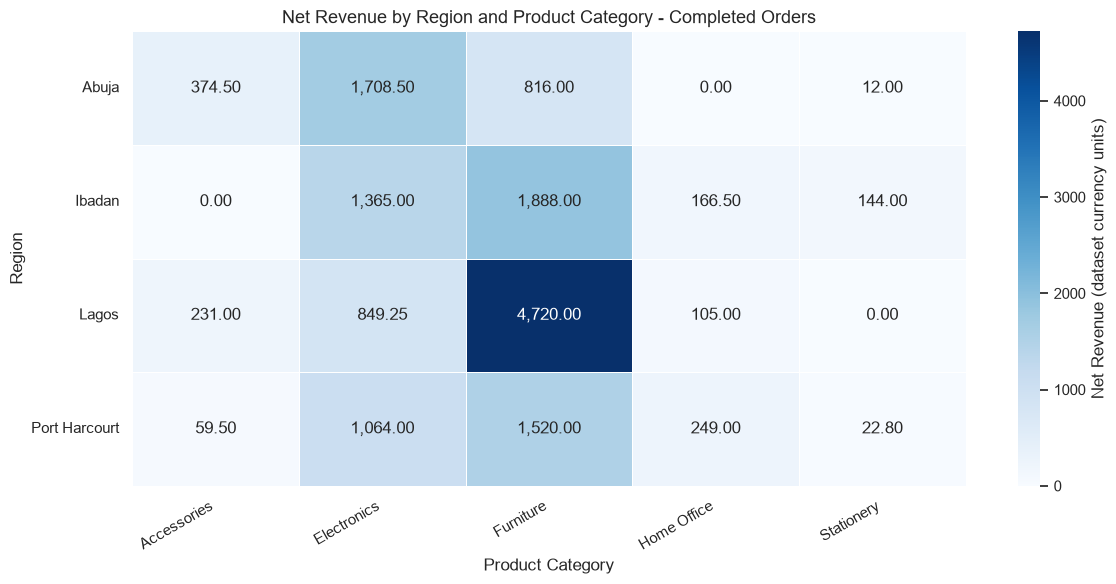

In [26]:
# Step 25: Visualize regional revenue using a heatmap

fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    data=region_category_revenue,
    annot=True,
    fmt=",.2f",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={
        "label": "Net Revenue (dataset currency units)"
    },
    ax=ax
)

ax.set_title(
    "Net Revenue by Region and Product Category - Completed Orders",
    fontsize=13
)

ax.set_xlabel("Product Category")
ax.set_ylabel("Region")

plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)

fig.tight_layout()

# Save the heatmap
figure_path = (
    figures_dir / "region_category_revenue_heatmap.png"
)

fig.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight"
)

print("Heatmap saved to:", figure_path)

plt.show()

### EDA Finding 3: Regional Revenue and Product Mix

Lagos recorded the highest completed-order net revenue
(5,905.25), despite Abuja having the highest completed-order
count (15 compared with Lagos's 14).

Lagos generated 4,720.00 in Furniture revenue, representing
approximately 79.93% of its total completed-order revenue.

Abuja generated more Electronics revenue than Lagos, but
substantially less Furniture revenue.

**Business interpretation:**

Product mix is an important factor associated with regional
revenue differences. High-value Standing Desk transactions
contribute heavily to Lagos's revenue performance.

These observations describe the available sample and do not
establish that location causes differences in purchasing behavior.

## 7. Time-Based Exploratory Data Analysis

### 7.1 Date Preparation

**Business question:** How does completed-order revenue
change over time?

We will convert transaction dates into datetime format
and examine the periods covered by the dataset.

In [27]:
# Step 26: Prepare dates for temporal analysis

# Convert the string dates into Pandas datetime values.
df["order_date"] = pd.to_datetime(
    df["order_date"],
    format="%Y-%m-%d"
)

completed_df["order_date"] = pd.to_datetime(
    completed_df["order_date"],
    format="%Y-%m-%d"
)

print("Date column type:")
print(completed_df["order_date"].dtype)

print("\nEarliest completed order:")
print(completed_df["order_date"].min())

print("\nLatest completed order:")
print(completed_df["order_date"].max())

print("\nFirst five completed order dates:")
display(completed_df[["order_id", "order_date"]].head())

Date column type:
datetime64[us]

Earliest completed order:
2026-07-02 00:00:00

Latest completed order:
2026-09-26 00:00:00

First five completed order dates:


,order_id,order_date
0,ORD-1001,2026-07-04
1,ORD-1002,2026-07-12
3,ORD-1004,2026-08-23
4,ORD-1005,2026-08-13
7,ORD-1008,2026-09-12


### 7.2 Monthly Revenue Analysis

Aggregate completed-order revenue by month to investigate
changes in transaction volume and revenue over time.

In [28]:
# Step 27: Calculate monthly completed-order revenue
# Extract year and month from the transaction date.
completed_df["analysis_month"] = (
    completed_df["order_date"].dt.to_period("M")
)

# Group the completed orders by month.
monthly_performance = (
    completed_df
    .groupby("analysis_month")
    .agg(
        completed_orders=("order_id", "nunique"),
        total_revenue=("net_revenue", "sum"),
        average_order_value=("net_revenue", "mean")
    )
    .sort_index()
)

print("Monthly completed-order performance:")
display(monthly_performance.round(2))

# Reconcile the totals with our earlier analysis.
print(
    "\nTotal completed orders:",
    monthly_performance["completed_orders"].sum()
)

print(
    "Total completed revenue:",
    f"{monthly_performance['total_revenue'].sum():,.2f}"
)

Monthly completed-order performance:


,completed_orders,total_revenue,average_order_value
analysis_month,,,
2026-07,20,5967.80,298.39
2026-08,20,7621.25,381.06
2026-09,11,1706.00,155.09



Total completed orders: 51
Total completed revenue: 15,295.05


### 7.3 Monthly Revenue Trend Visualization

**Business question:** How did completed-order revenue
change across the observed months?

Visualize monthly revenue chronologically and investigate
whether changes correspond to order counts or average
transaction values.

In [29]:
# Step 28: Prepare monthly data for visualization

monthly_plot_data = monthly_performance.reset_index()

# Convert the monthly Period values into datetime timestamps.
monthly_plot_data["month_date"] = (
    monthly_plot_data["analysis_month"].dt.to_timestamp()
)

print("Monthly plotting dataset:")
display(monthly_plot_data)

Monthly plotting dataset:


,analysis_month,completed_orders,total_revenue,average_order_value,month_date
0,2026-07,20,5967.80,298.390000,2026-07-01
1,2026-08,20,7621.25,381.062500,2026-08-01
2,2026-09,11,1706.00,155.090909,2026-09-01


Figure saved to: c:\Users\User\Desktop\ml-engineering-foundations\eda\retail_sales_eda\outputs\figures\monthly_revenue_completed.png


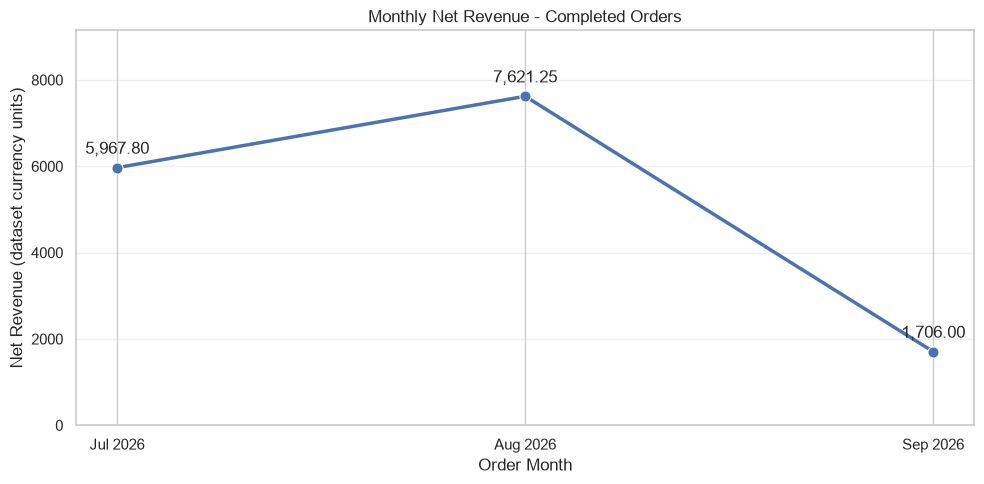

In [30]:
# Step 29: Visualize monthly completed-order revenue

import matplotlib.dates as mdates

fig, ax = plt.subplots(figsize=(10, 5))

sns.lineplot(
    data=monthly_plot_data,
    x="month_date",
    y="total_revenue",
    marker="o",
    linewidth=2.5,
    markersize=8,
    ax=ax
)

# Add the actual revenue amount above each point.
for _, row in monthly_plot_data.iterrows():
    ax.annotate(
        f"{row['total_revenue']:,.2f}",
        xy=(row["month_date"], row["total_revenue"]),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center"
    )

# Format the timeline.
ax.set_xticks(monthly_plot_data["month_date"])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

ax.set_title("Monthly Net Revenue - Completed Orders")
ax.set_xlabel("Order Month")
ax.set_ylabel("Net Revenue (dataset currency units)")

ax.set_ylim(
    0,
    monthly_plot_data["total_revenue"].max() * 1.2
)

ax.grid(axis="y", alpha=0.3)

fig.tight_layout()

# Save the figure for the portfolio.
figure_path = figures_dir / "monthly_revenue_completed.png"

fig.savefig(
    figure_path,
    dpi=150,
    bbox_inches="tight"
)

print("Figure saved to:", figure_path)

plt.show()

### 7.4 Monthly Revenue by Product Category

**Business question:** Which product categories contributed
to the increase in revenue between July and August 2026?

This analysis compares the revenue contribution of each
product category across the observed months.

Only completed orders are included.

In [31]:
# Step 30: Calculate monthly revenue by product category

monthly_category_revenue = completed_df.pivot_table(
    index="analysis_month",
    columns="category",
    values="net_revenue",
    aggfunc="sum",
    fill_value=0
).sort_index()

print("Monthly revenue by product category:")

display(monthly_category_revenue.round(2))

# Verify that revenue has been preserved.
print(
    "\nTotal completed revenue:",
    f"{monthly_category_revenue.to_numpy().sum():,.2f}"
)

Monthly revenue by product category:


category,Accessories,Electronics,Furniture,Home Office,Stationery
analysis_month,,,,,
2026-07,140.0,1486.50,3936.0,334.5,70.8
2026-08,185.5,2184.75,5008.0,135.0,108.0
2026-09,339.5,1315.50,0.0,51.0,0.0



Total completed revenue: 15,295.05


In [32]:
# Step 31: Compare category revenue between July and August

# Identify the monthly periods we want to compare.
july = pd.Period("2026-07", freq="M")
august = pd.Period("2026-08", freq="M")

# Build a comparison table.
monthly_comparison = pd.DataFrame({
    "July Revenue": monthly_category_revenue.loc[july],
    "August Revenue": monthly_category_revenue.loc[august]
})

# Calculate the revenue difference for each category.
monthly_comparison["Revenue Change"] = (
    monthly_comparison["August Revenue"]
    - monthly_comparison["July Revenue"]
)

# Sort by the largest positive change.
monthly_comparison = monthly_comparison.sort_values(
    "Revenue Change",
    ascending=False
)

print("July vs August category revenue comparison:")

display(monthly_comparison.round(2))

print(
    "\nOverall revenue change:",
    f"{monthly_comparison['Revenue Change'].sum():,.2f}"
)

July vs August category revenue comparison:


,July Revenue,August Revenue,Revenue Change
category,,,
Furniture,3936.0,5008.00,1072.00
Electronics,1486.5,2184.75,698.25
Accessories,140.0,185.50,45.50
Stationery,70.8,108.00,37.20
Home Office,334.5,135.00,-199.50



Overall revenue change: 1,653.45


### 7.5 Investigation of High-Value Transactions

**Business question:** What explains the increase in
Furniture revenue between July and August?

We will inspect completed Standing Desk transactions,
including order dates, quantities, prices, discounts,
and net revenue.

In [33]:
# Step 32: Investigate completed Standing Desk transactions

standing_desk_orders = (
    completed_df.loc[
        completed_df["product"] == "Standing Desk",
        [
            "order_id",
            "order_date",
            "analysis_month",
            "region",
            "quantity",
            "unit_price",
            "discount_pct",
            "net_revenue"
        ]
    ]
    .sort_values("order_date")
)

print("Completed Standing Desk transactions:")
display(standing_desk_orders)

print(
    "\nTotal completed Standing Desk orders:",
    len(standing_desk_orders)
)

print(
    "Total Standing Desk revenue:",
    f"{standing_desk_orders['net_revenue'].sum():,.2f}"
)

Completed Standing Desk transactions:


,order_id,order_date,analysis_month,region,quantity,unit_price,discount_pct,net_revenue
47,ORD-1048,2026-07-02,2026-07,Lagos,5,320.0,0.0,1600.0
1,ORD-1002,2026-07-12,2026-07,Lagos,5,320.0,5.0,1520.0
20,ORD-1021,2026-07-14,2026-07,Abuja,3,320.0,15.0,816.0
64,ORD-1065,2026-08-09,2026-08,Ibadan,4,320.0,0.0,1280.0
59,ORD-1060,2026-08-21,2026-08,Lagos,5,320.0,0.0,1600.0
3,ORD-1004,2026-08-23,2026-08,Ibadan,2,320.0,5.0,608.0
74,ORD-1075,2026-08-24,2026-08,Port Harcourt,5,320.0,5.0,1520.0



Total completed Standing Desk orders: 7
Total Standing Desk revenue: 8,944.00


In [34]:
# Step 33: Summarize Standing Desk performance by month

standing_desk_monthly = (
    standing_desk_orders
    .groupby("analysis_month")
    .agg(
        completed_orders=("order_id", "nunique"),
        units_sold=("quantity", "sum"),
        total_revenue=("net_revenue", "sum"),
        average_order_value=("net_revenue", "mean")
    )
    .sort_index()
)

print("Monthly Standing Desk performance:")
display(standing_desk_monthly.round(2))

Monthly Standing Desk performance:


,completed_orders,units_sold,total_revenue,average_order_value
analysis_month,,,,
2026-07,3,13,3936.0,1312.0
2026-08,4,16,5008.0,1252.0


### EDA Finding 4: Standing Desk Revenue Growth

Furniture revenue increased from 3,936.00 in July to
5,008.00 in August, an increase of 1,072.00 (27.24%).

Further investigation revealed:

- Completed Standing Desk orders increased from 3 to 4.
- Units sold increased from 13 to 16.
- Average order value decreased from 1,312.00 to 1,252.00.

**Business interpretation:**

The revenue increase was driven by a higher number of
completed Standing Desk transactions, despite a decline
in average order value.

This demonstrates why analyzing revenue alone is
insufficient to explain changes in sales performance.

Unlike an ordinary bar chart, which compares one metric across groups, a stacked bar chart shows both the total and how different components contribute to that total.

### 7.6 Monthly Revenue Composition by Category

Visualize how each product category contributes to monthly
completed-order revenue.

Objective: Investigate how changes in product mix relate
to monthly sales performance.

Figure saved to: C:\Users\User\Desktop\ml-engineering-foundations\eda\retail_sales_eda\outputs\figures\monthly_category_revenue_stacked.png


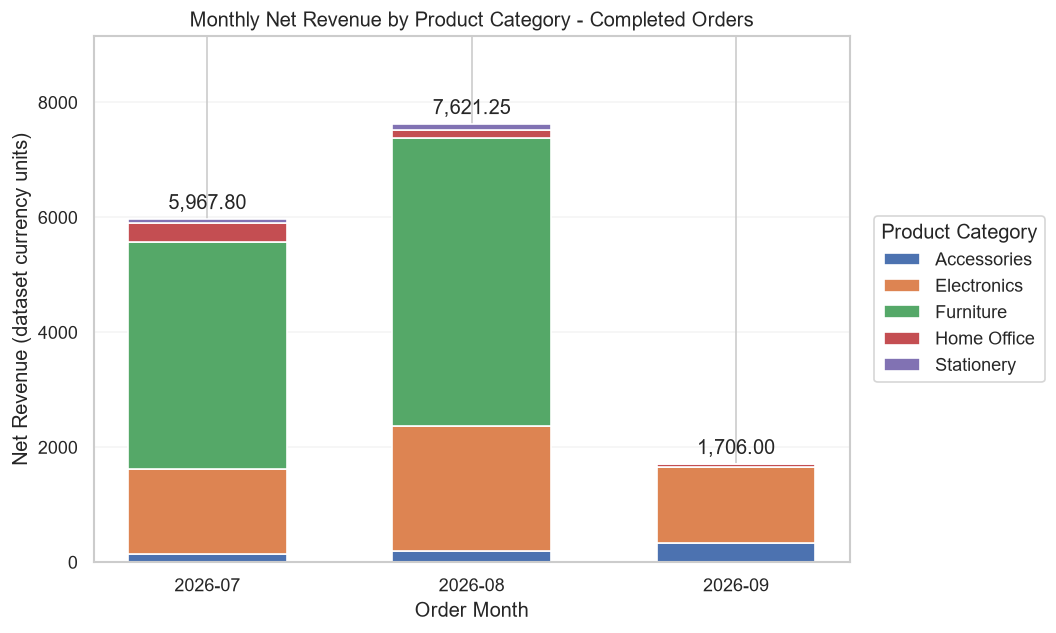

In [38]:
# Step 34: Monthly revenue by product category
# Corrected version with controlled figure dimensions.

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# Close any previously active Matplotlib figures.
plt.close("all")

# Prepare the monthly revenue data.
plot_data = monthly_category_revenue.astype(float).copy()

# Create numerical positions for the months.
x = np.arange(len(plot_data))

# Track the height of each stacked bar.
bottom = np.zeros(len(plot_data))

# Create a figure with explicit dimensions.
fig, ax = plt.subplots(figsize=(10, 6), dpi=120)

# Draw each product category.
for category in plot_data.columns:

    values = plot_data[category].to_numpy()

    ax.bar(
        x,
        values,
        bottom=bottom,
        width=0.6,
        label=category
    )

    # Update the stack height.
    bottom += values

# Display total revenue above each month.
for i, total in enumerate(bottom):
    ax.annotate(
        f"{total:,.2f}",
        xy=(i, total),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center"
    )

# Format the chart.
ax.set_xticks(x)
ax.set_xticklabels([str(month) for month in plot_data.index])

ax.set_title(
    "Monthly Net Revenue by Product Category - Completed Orders"
)

ax.set_xlabel("Order Month")
ax.set_ylabel("Net Revenue (dataset currency units)")

ax.set_ylim(0, bottom.max() * 1.2)

ax.legend(
    title="Product Category",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5)
)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

# Manually allocate space for the legend.
fig.subplots_adjust(
    left=0.12,
    right=0.75,
    bottom=0.15,
    top=0.88
)

# Save without bbox_inches="tight".
figure_path = (
    figures_dir / "monthly_category_revenue_stacked.png"
)

fig.savefig(
    figure_path,
    dpi=120
)

print("Figure saved to:", figure_path.resolve())

plt.show()


What is correlation?
Correlation measures the direction and strength of an association between numerical variables.
A common measure is the Pearson correlation coefficient, denoted by \(r\)

it is used to measure association, from  -1 to +1. The former means stong negative correlation and the latter means strong positive correlation. values near 0 indicate little linear association

## 8. Numerical Relationships and Correlation Analysis

### 8.1 Quantity vs Net Revenue

**Business question:** Is order quantity associated with
net revenue for completed transactions?

We will use a scatter plot to investigate the relationship
and identify unusual observations.

Only completed orders are included.

Figure saved to: C:\Users\User\Desktop\ml-engineering-foundations\eda\retail_sales_eda\outputs\figures\quantity_vs_revenue_scatter.png


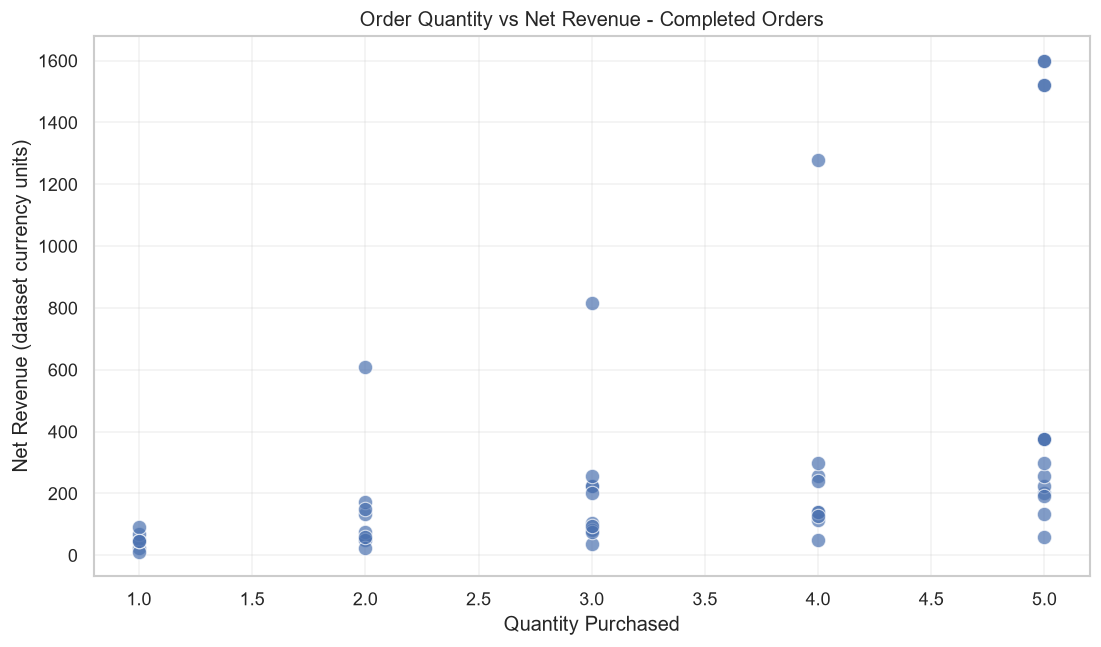

In [41]:
# Step 35: Investigate quantity versus net revenue
fig, ax = plt.subplots(figsize=(10, 6), dpi=120)

sns.scatterplot(
    data=completed_df,
    x="quantity",
    y="net_revenue",
    s=75,
    alpha=0.7,
    ax=ax
)

ax.set_title(
    "Order Quantity vs Net Revenue - Completed Orders"
)

ax.set_xlabel("Quantity Purchased")
ax.set_ylabel("Net Revenue (dataset currency units)")

ax.grid(alpha=0.25)
ax.set_axisbelow(True)

# Keep figure dimensions controlled.
fig.subplots_adjust(
    left=0.12,
    right=0.95,
    bottom=0.15,
    top=0.90
)

# Save the visualization.
figure_path = figures_dir / "quantity_vs_revenue_scatter.png"

fig.savefig(figure_path, dpi=120)

print("Figure saved to:", figure_path.resolve())

plt.show()

In [42]:
# Step 36: Calculate Pearson correlation

quantity_revenue_corr = completed_df[
    ["quantity", "net_revenue"]
].corr(method="pearson")

print("Correlation matrix:")
display(quantity_revenue_corr.round(3))

# Extract the individual correlation coefficient.
r = quantity_revenue_corr.loc["quantity", "net_revenue"]

print(f"\nQuantity vs Net Revenue correlation: {r:.3f}")

Correlation matrix:


,quantity,net_revenue
quantity,1.000,0.468
net_revenue,0.468,1.000



Quantity vs Net Revenue correlation: 0.468


Net Revenue= Quantity x Unit Price x Discount

### 8.2 Correlation Sensitivity Analysis

**Analytical question:** How does the relationship between
quantity and net revenue change when Standing Desk
transactions are excluded?

All completed orders are retained in the primary analysis.

Excluding Standing Desk transactions is used only as a
sensitivity check, not as a data-cleaning decision.

In [43]:
# Step 37: Compare correlations with and without Standing Desks

# Correlation across all completed orders
all_orders_corr = completed_df[
    "quantity"
].corr(completed_df["net_revenue"])

# Create a subset excluding Standing Desk transactions.
other_orders_df = completed_df.loc[
    completed_df["product"] != "Standing Desk"
].copy()

# Calculate correlation for the remaining orders.
other_orders_corr = other_orders_df[
    "quantity"
].corr(other_orders_df["net_revenue"])

print("All completed orders:", len(completed_df))
print("Other product orders:", len(other_orders_df))

print(
    f"\nCorrelation (all completed orders): "
    f"{all_orders_corr:.3f}"
)

print(
    f"Correlation (excluding Standing Desks): "
    f"{other_orders_corr:.3f}"
)

All completed orders: 51
Other product orders: 44

Correlation (all completed orders): 0.468
Correlation (excluding Standing Desks): 0.678


Figure saved to: C:\Users\User\Desktop\ml-engineering-foundations\eda\retail_sales_eda\outputs\figures\quantity_revenue_product_groups.png


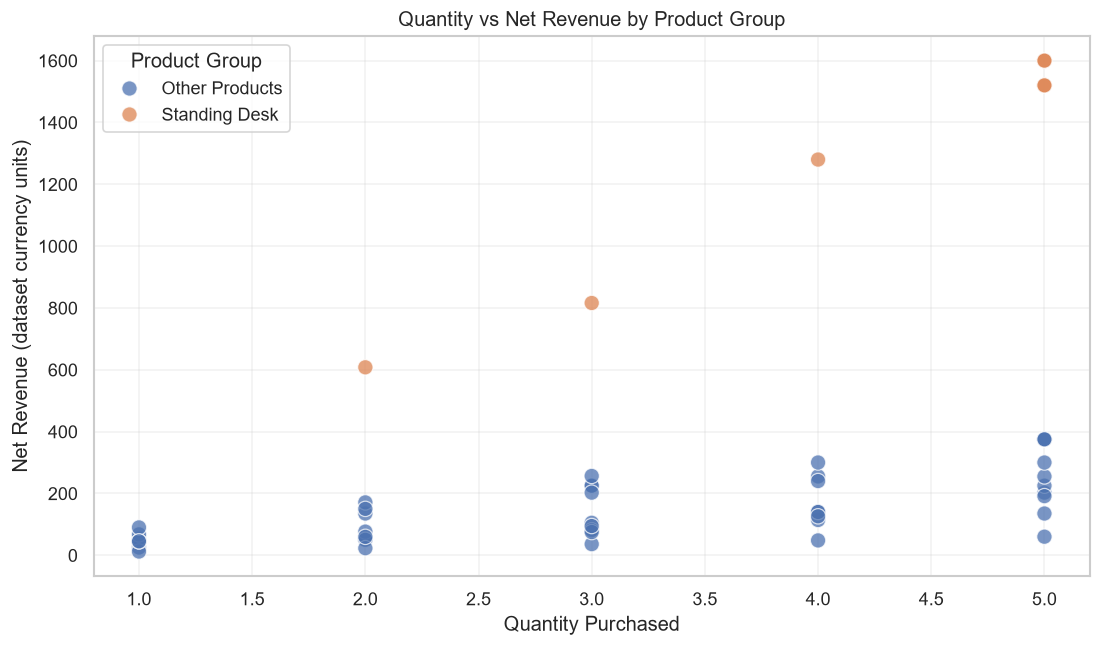

In [44]:

# Step 38: Compare Standing Desk transactions with other products

# Create a temporary plotting DataFrame.
scatter_data = completed_df.copy()

# Classify transactions for visual comparison.
scatter_data["product_group"] = (
    scatter_data["product"]
    .eq("Standing Desk")
    .map({
        True: "Standing Desk",
        False: "Other Products"
    })
)

fig, ax = plt.subplots(figsize=(10, 6), dpi=120)

sns.scatterplot(
    data=scatter_data,
    x="quantity",
    y="net_revenue",
    hue="product_group",
    s=85,
    alpha=0.75,
    ax=ax
)

ax.set_title(
    "Quantity vs Net Revenue by Product Group"
)

ax.set_xlabel("Quantity Purchased")
ax.set_ylabel("Net Revenue (dataset currency units)")

ax.legend(
    title="Product Group",
    loc="upper left"
)

ax.grid(alpha=0.25)
ax.set_axisbelow(True)

fig.subplots_adjust(
    left=0.12,
    right=0.95,
    bottom=0.15,
    top=0.90
)

figure_path = figures_dir / "quantity_revenue_product_groups.png"

fig.savefig(
    figure_path,
    dpi=120
)

print("Figure saved to:", figure_path.resolve())

plt.show()



### EDA Finding 5: Product Mix and Correlation

The Pearson correlation between order quantity and net revenue
was 0.468 across all 51 completed orders, indicating a
moderate positive linear association.

After excluding Standing Desk transactions, the correlation
increased to 0.678 across the remaining 44 completed orders.

**Interpretation:**

The relationship between quantity and net revenue is sensitive
to product composition. High-value Standing Desk transactions
form a distinct group with substantially greater revenue than
most other transactions.

This demonstrates why overall correlations should be examined
alongside scatter plots and subgroup analyses.

The analysis does not establish causation, and no transactions
were permanently removed.


### 8.3 Numerical Correlation Matrix

**Analytical question:** Which numerical features are strongly
associated with one another?

We will calculate Pearson correlation coefficients across
the numerical variables of completed orders.

Some revenue features are mathematically derived from others.
These dependencies must be considered when interpreting
the results.

In [46]:
# Step 39: Calculate correlations between numerical variables

numeric_columns = [
    "quantity",
    "unit_price",
    "discount_pct",
    "gross_revenue",
    "discount_amount",
    "net_revenue"
]

# Select numerical variables from completed orders.
numeric_df = completed_df[numeric_columns]

# Calculate Pearson correlations.
correlation_matrix = numeric_df.corr(
    method="pearson"
)

print("Numerical correlation matrix:")

display(correlation_matrix.round(3))

Numerical correlation matrix:


,quantity,unit_price,discount_pct,gross_revenue,discount_amount,net_revenue
quantity,1.000,0.252,-0.081,0.466,0.178,0.468
unit_price,0.252,1.000,-0.032,0.936,0.546,0.928
discount_pct,-0.081,-0.032,1.000,-0.089,0.512,-0.123
gross_revenue,0.466,0.936,-0.089,1.000,0.475,0.999
discount_amount,0.178,0.546,0.512,0.475,1.000,0.428
net_revenue,0.468,0.928,-0.123,0.999,0.428,1.000


### 8.4 Correlation Heatmap

Visualize the direction and strength of linear relationships
between numerical variables.

The analysis will consider mathematical dependencies,
product mix, and possible implications for Machine Learning.

Figure saved to: C:\Users\User\Desktop\ml-engineering-foundations\eda\retail_sales_eda\outputs\figures\numerical_correlation_heatmap.png


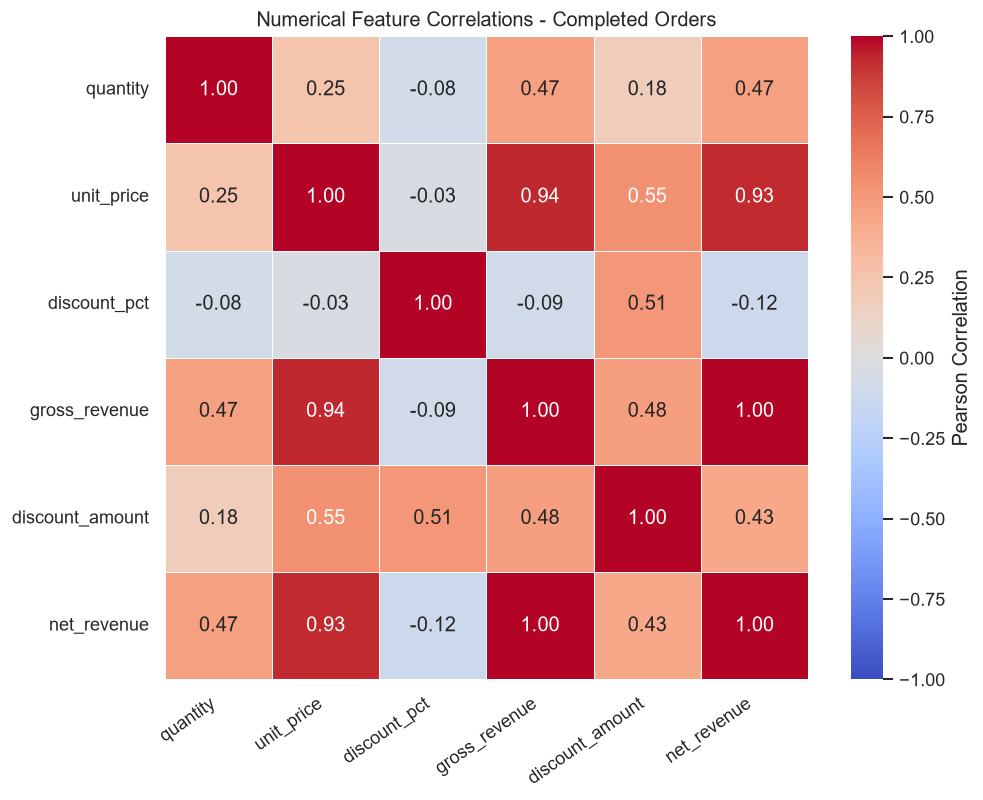

In [47]:
# Step 40: Visualize numerical correlations

fig, ax = plt.subplots(figsize=(10, 8), dpi=120)

sns.heatmap(
    data=correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation"},
    ax=ax
)

ax.set_title(
    "Numerical Feature Correlations - Completed Orders"
)

ax.set_xticklabels(
    ax.get_xticklabels(),
    rotation=35,
    ha="right"
)

ax.set_yticklabels(
    ax.get_yticklabels(),
    rotation=0
)

# Use controlled spacing to avoid oversized image exports.
fig.subplots_adjust(
    left=0.20,
    right=0.92,
    bottom=0.23,
    top=0.90
)

# Save the figure.
figure_path = figures_dir / "numerical_correlation_heatmap.png"

fig.savefig(
    figure_path,
    dpi=120
)

print("Figure saved to:", figure_path.resolve())

plt.show()

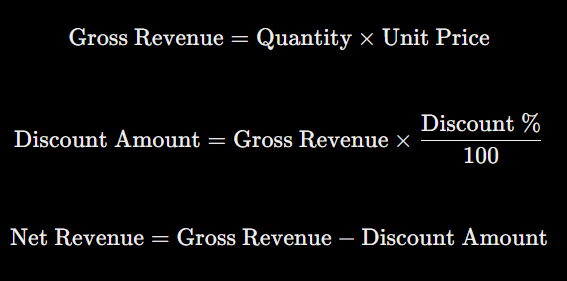

In [48]:
# Step 41: Identify strongest correlation pairs

import numpy as np

# Keep only the upper triangle of the matrix.
# k=1 excludes the diagonal, where variables correlate
# perfectly with themselves.

upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape, dtype=bool),
        k=1
    )
)

# Convert the remaining correlation values into a Series.
correlation_pairs = upper_triangle.stack()

# Identify the strongest positive and negative pairs.
strongest_positive = correlation_pairs.idxmax()
strongest_negative = correlation_pairs.idxmin()

print("Strongest positive correlation:")
print(strongest_positive, correlation_pairs.max().round(3))

print("\nMost negative correlation:")
print(strongest_negative, correlation_pairs.min().round(3))


Strongest positive correlation:
('gross_revenue', 'net_revenue') 0.999

Most negative correlation:
('discount_pct', 'net_revenue') -0.123


## Executive Summary

This exploratory data analysis examined 80 retail orders, including 51 completed transactions generating 15,295.05 in net revenue.

The analysis identified three business findings concerning payment methods, regional performance, and revenue concentration.

### Finding 1: Payment Method Usage

**Observation:** Card payments accounted for 21 of the 51 completed orders (41.18%), making Card the most frequently recorded payment method among completed transactions.

**Business implication:** Card payments represent an important part of successfully completed transactions. However, completed-order counts alone cannot establish customers' overall payment preferences.

**Recommendation:** Maintain multiple payment options while investigating payment success rates, transaction values, processing costs, and whether larger purchases are associated with particular payment methods.

### Finding 2: Regional Revenue Performance

**Observation:** Lagos generated the highest completed-order net revenue (5,905.25), despite Abuja recording more completed orders. Standing Desk transactions contributed 4,720.00, approximately 79.93% of Lagos's revenue.

**Business implication:** High-value Standing Desk transactions are a major contributor to Lagos's recorded revenue performance. However, this also indicates potential dependence on a single product.

**Recommendation:** Monitor Standing Desk inventory in Lagos and investigate regional profitability, product availability, and longer-term sales patterns before increasing inventory investment.

### Finding 3: Revenue Concentration Risk

**Observation:** Seven completed Standing Desk transactions generated 8,944.00, accounting for 58.48% of total completed revenue, despite representing only 13.73% of completed orders.

**Business implication:** A relatively small number of high-value transactions contribute disproportionately to revenue. If demand for Standing Desks declines or inventory becomes unavailable, overall revenue could be significantly affected.

**Recommendation:** Investigate opportunities to strengthen other product categories, particularly Electronics, which recorded the highest completed-order volume. Evaluate product profitability, repeat purchases, inventory risks, and demand stability before changing the product portfolio.

### Overall Conclusion

The business demonstrates two distinct sales patterns: higher transaction frequency in Electronics and substantially higher transaction values in Furniture.

Maintaining a diversified product portfolio while monitoring high-value products could help manage revenue concentration risk.

These findings are based on a limited three-month dataset and should be validated using additional historical, inventory, and profitability data before major business decisions are made.